Load the `ISLR2` and `tidyverse` packages.

In [7]:
library(tidymodels)
library(ISLR2)
library(tidyverse)

── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.13     ✔ rsample      1.3.2 
✔ dials        1.4.4      ✔ tailor       0.1.0 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ recipes      1.3.3      ✔ yardstick    1.4.0 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filter()   masks stats::filter()
✖ recipes::fixed()  masks stringr::fixed()
✖ dplyr::lag()      masks stats::lag()
✖ yardstick::spec() masks readr::spec()
✖ recipes::step()   masks stats::step()



`glimpse` the `Auto` dataset (this comes from the `ISLR2` package).

In [8]:
glimpse(Auto)

Rows: 392
Columns: 9
$ mpg          <dbl> 18, 15, 18, 16, 17, 15, 14, 14, 14, 15, 15, 14, 15, 14, 2…
$ cylinders    <int> 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 4, 6, 6, 6, 4, …
$ displacement <dbl> 307, 350, 318, 304, 302, 429, 454, 440, 455, 390, 383, 34…
$ horsepower   <int> 130, 165, 150, 150, 140, 198, 220, 215, 225, 190, 170, 16…
$ weight       <int> 3504, 3693, 3436, 3433, 3449, 4341, 4354, 4312, 4425, 385…
$ acceleration <dbl> 12.0, 11.5, 11.0, 12.0, 10.5, 10.0, 9.0, 8.5, 10.0, 8.5, …
$ year         <int> 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 70, 7…
$ origin       <int> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 3, …
$ name         <fct> chevrolet chevelle malibu, buick skylark 320, plymouth sa…


Plot `mpg`  as a function of `displacement`.

`geom_smooth()` using formula = 'y ~ x'


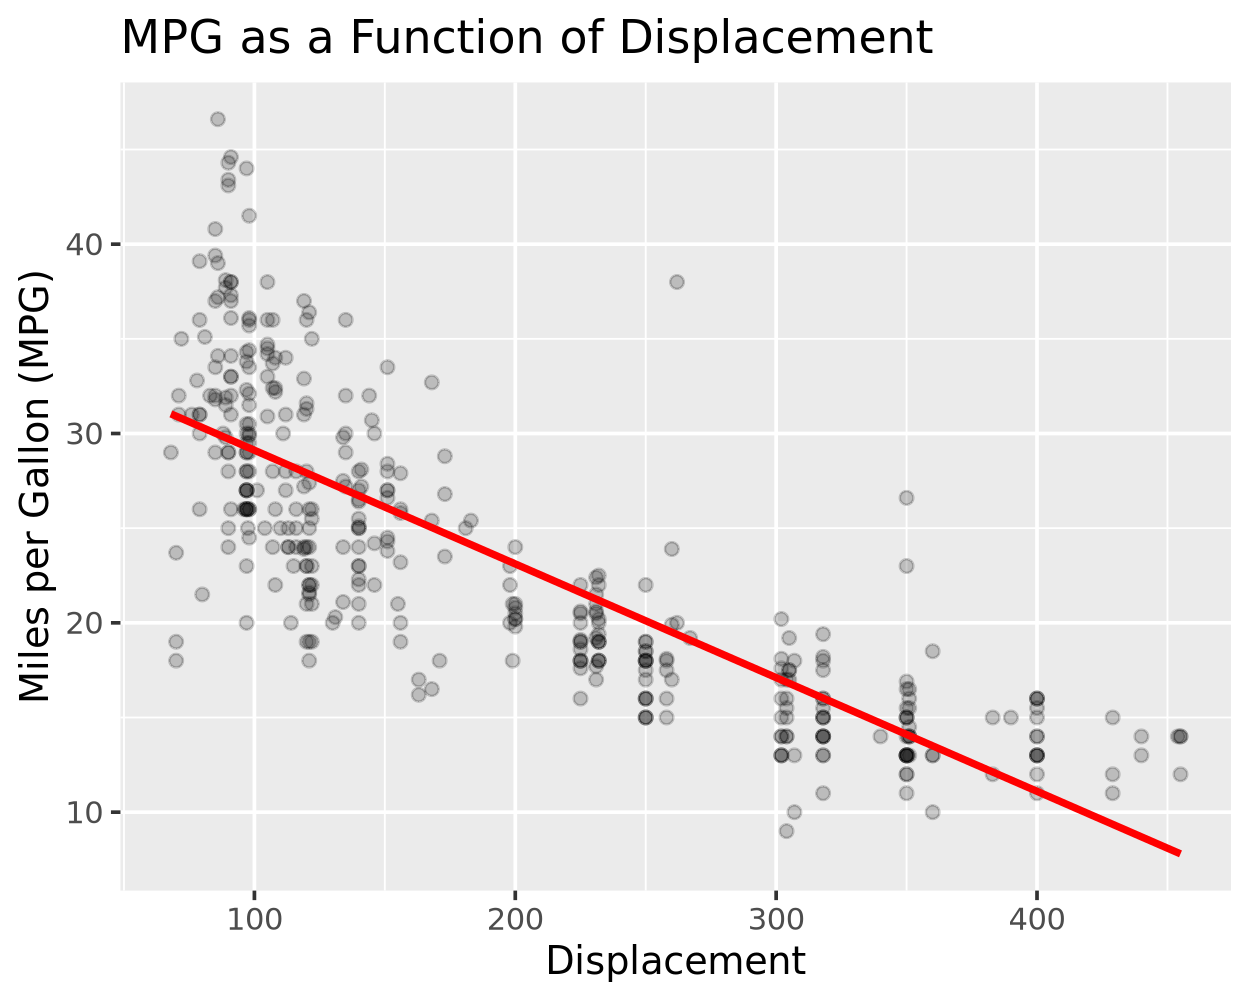

In [9]:
ggplot(Auto, aes(x = displacement, y = mpg)) + 
    geom_point(alpha = 0.2) +
    geom_smooth(method = "lm", se = FALSE, color = "red") +
      labs(
        title = "MPG as a Function of Displacement",
        x = "Displacement",
        y = "Miles per Gallon (MPG)"
  )

❓Does the relationship of `mpg` to `displacement` look linear?

The relationship beteween mpg and displacement appears as a linear and negative. 



Model `mpg` as a function of `displacement` and `cylinders`. 

- Transform the `displacement` variable using a `spline` or `polynomial` transform. (Hint: use `step_ns` or `step_poly`).
- Combine `step_mutate(cyl_cat = factor(cylinders))` followed by `step_dummy(cyl_cat)` and `step_rm(cylinders)` to convert `cylinders` to categorical data for the model.

Assuming you name your fitted model `mod_fit` the code below can be used to visualize your model:

```r
predict(mod_fit, rec |> juice()) |>
    bind_cols(Auto) |>
ggplot(aes(x = displacement, y = mpg)) +
    geom_point(size = 1, alpha = 0.35) +
    geom_line(aes(y = .pred, color = factor(cylinders)), linewidth = 1)
```

**Create and visualize your model below...**

In [18]:
rec = recipe(mpg ~ displacement + cylinders, data = Auto) |>
    step_ns(displacement, deg_free = 3) |>
    step_mutate(cyl_cat = factor(cylinders)) |>
    step_dummy(cyl_cat) |>
    step_rm(cylinders)


mod = linear_reg() |> set_engine('lm')

In [19]:
# Create workflow
wf = workflow() |> add_recipe(rec) |> add_model(mod)

# Create 5-fold cross-validation
set.seed(123)
folds = vfold_cv(Auto, v = 5)

# Tune the model
tuned = tune_grid(
    wf,
    resamples = folds,
    grid = 5
)

# Select the best parameters
best_params = select_best(tuned, metric = "rmse")

# Finalize and fit the model
final_wf = finalize_workflow(wf, best_params)

mod_fit = fit(final_wf, data = Auto)

Warning message:
“No tuning parameters have been detected, performance will be evaluated using
the resamples with no tuning.
Did you want to assign any parameters with a value of `tune()`?”


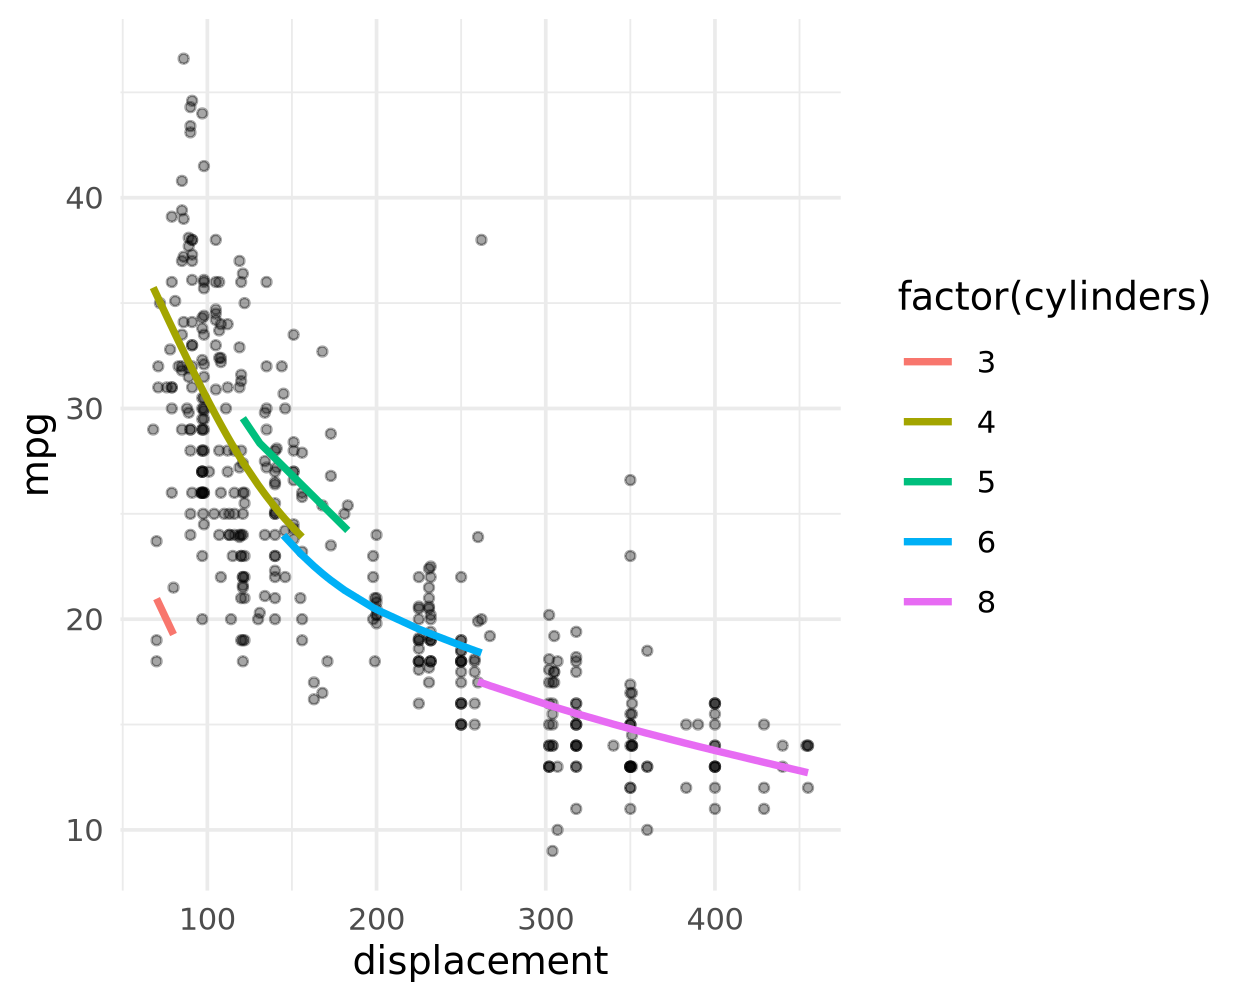

In [20]:
predict(mod_fit, Auto) |>
    bind_cols(Auto) |>
ggplot(aes(x = displacement, y = mpg)) +
    geom_point(size = 1, alpha = 0.35) +
    geom_line(aes(y = .pred, color = factor(cylinders)), linewidth = 1)+
theme_minimal()

